# FINAL RQ1 RESULTS — Forward Diagnosis Prediction

**Purpose:** Answer RQ1 by comparing Logistic Regression, Random Forest, SVM, XGBoost, MLP and a Bayesian Network on a shared MIMIC-IV heart-failure prediction task, using a patient-level train/validation/test split and the evaluation additions requested by Prof. Ajoodha.

This notebook is part of the final, unified MSc research pipeline described in the research proposal. It is designed to save intermediate artifacts to Google Drive so that long-running computations can resume after a Colab restart.

**Important:** the old processed splits and old model artifacts are not treated as final because the supervisor raised a patient-level split/data-leakage concern. The raw dataset may be reused, but the final pipeline rebuilds the split and downstream models from that raw data.


In [17]:

from google.colab import drive
drive.mount("/content/drive")

import os, json, pickle, shutil, hashlib, time, warnings
from pathlib import Path

PIPELINE_VERSION = "FINAL_2026-09-24_v1"
RANDOM_STATE = 42

DRIVE_ROOT = Path("/content/drive/MyDrive/heart_failure_bn_FINAL")
DIRS = {
    "root": DRIVE_ROOT,
    "checkpoints": DRIVE_ROOT / "checkpoints",
    "models": DRIVE_ROOT / "models",
    "predictions": DRIVE_ROOT / "predictions",
    "results": DRIVE_ROOT / "results",
    "figures": DRIVE_ROOT / "figures",
    "logs": DRIVE_ROOT / "logs",
    "data": DRIVE_ROOT / "data",
    "templates": DRIVE_ROOT / "templates",
}
for p in DIRS.values():
    p.mkdir(parents=True, exist_ok=True)

LEGACY_ROOT = Path("/content/drive/MyDrive/heart_failure_bn_checkpoints")
print("FINAL Drive folder:", DRIVE_ROOT)
print("Pipeline version:", PIPELINE_VERSION)

# We may reuse the raw dataset only. Old processed splits/models are deliberately NOT reused.
legacy_raw = LEGACY_ROOT / "raw_master_dataset.pkl"
final_raw = DIRS["data"] / "raw_master_dataset.pkl"
if not final_raw.exists() and legacy_raw.exists():
    shutil.copy2(legacy_raw, final_raw)
    print("Copied legacy raw dataset into FINAL project folder.")
print("Raw dataset available:", final_raw.exists())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
FINAL Drive folder: /content/drive/MyDrive/heart_failure_bn_FINAL
Pipeline version: FINAL_2026-09-24_v1
Raw dataset available: True


## Research alignment

The proposal defines RQ1 as the comparison of five standard classifiers against the Bayesian Network for predicting the target heart-failure diagnosis using precision, recall, F1-score and AUROC. The proposal also specifies a common feature set, training-only imputation, a 70/15/15 split, 5-fold CV for tuning, and bootstrap confidence intervals.

The final implementation additionally includes AUPRC, Brier score and calibration for all six models, a fixed 0.50 classification threshold, Holm correction across the 15 DeLong comparisons, AUROC effect sizes, and a BN sensitivity analysis. These additions directly address the supervisor feedback.


In [18]:

# =========================
# 1. INSTALL / IMPORT
# =========================
!pip install -q pgmpy xgboost statsmodels

import numpy as np
import pandas as pd
import json, pickle, time, warnings, itertools, os, math
from pathlib import Path

from google.cloud import bigquery
from google.colab import auth

from sklearn.model_selection import GroupShuffleSplit, ParameterGrid, StratifiedKFold, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    precision_score, recall_score, f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, classification_report, brier_score_loss
)
from sklearn.calibration import calibration_curve
from scipy.stats import norm
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
np.random.seed(RANDOM_STATE)
CV_FOLDS = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

TARGET = "heart_failure"
CLASSIFICATION_THRESHOLD = 0.50
BOOTSTRAPS = 1000

print("Libraries ready.")


Libraries ready.


## 2. Load the raw cohort and perform pre-rerun validity checks

The study outcome is operationalised as **heart failure**, not specifically acute heart failure.
This decision follows review of the observed ICD-coded positive cohort: acute, chronic, acute-on-chronic,
and unspecified/other heart-failure codes are all present. Therefore, the existing I50.x-based cohort is retained,
but the outcome terminology is changed to **heart failure** throughout the experimental pipeline.

Do not proceed to training until the printed ICD-code distribution has been reviewed and the target terminology
is recorded in the run manifest.


In [19]:

raw_path = DIRS["data"] / "raw_master_dataset.pkl"
if raw_path.exists():
    df = pd.read_pickle(raw_path)
else:
    auth.authenticate_user()
    client = bigquery.Client(project="research-heart-failure")
    df = client.query(
        "SELECT * FROM `research-heart-failure.Research.master_dataset_fixed`"
    ).to_dataframe()
    df.to_pickle(raw_path)

print("Raw dataset shape:", df.shape)
print("Columns:", len(df.columns))

if "heart_failure_icd_codes" in df.columns:
    positive_codes = (
        df.loc[df[TARGET] == 1, "heart_failure_icd_codes"]
        .astype(str)
        .value_counts(dropna=False)
    )
    print("\nPositive ICD-code distribution:")
    print(positive_codes.to_string())
    positive_codes.to_csv(DIRS["results"] / "target_icd_code_distribution.csv")

print("\nOutcome prevalence:", df[TARGET].mean())
print("Unique patients:", df["subject_id"].nunique() if "subject_id" in df.columns else "subject_id missing")

manifest = {
    "target_label": "heart failure",
    "target_definition_confirmed": True,
    "pipeline_version": PIPELINE_VERSION,
    "raw_shape": list(df.shape),
    "prevalence": float(df[TARGET].mean()),
    "n_unique_subjects": int(df["subject_id"].nunique()) if "subject_id" in df.columns else None,
}
with open(DIRS["checkpoints"] / "run_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)


Raw dataset shape: (94458, 73)
Columns: 73

Positive ICD-code distribution:
heart_failure_icd_codes
['I5033']                      2833
['I5023']                      2506
['I5032']                      2373
['4280' '42833']               1979
['I5022']                      1944
['4280' '42832']               1879
['4280' '42823']               1871
['4280' '42822']               1621
['4280']                       1598
['I5021']                      1045
['I509']                        942
['4280' '42821']                723
['4280' '42843']                549
['I5031']                       491
['4280' '42831']                483
['I5020']                       389
['I5030']                       365
['I5043']                       362
['4280' '42830']                263
['4280' '42842']                244
['4280' '42820']                165
['I5042']                       133
['4280' '42841']                 85
['I5041']                        71
['I5023' 'I5084']                60


In [20]:
# =========================
# VALIDITY CHECKS
# =========================
required_cols = ["subject_id", TARGET]
missing_required = [c for c in required_cols if c not in df.columns]
assert not missing_required, f"Missing required columns: {missing_required}"

# Literal duplicate check while safely handling object columns that contain
# numpy arrays/lists/dicts. pandas duplicated() requires hashable cell values.
def _make_hashable(x):
    if isinstance(x, np.ndarray):
        return tuple(_make_hashable(v) for v in x.tolist())
    if isinstance(x, (list, tuple)):
        return tuple(_make_hashable(v) for v in x)
    if isinstance(x, dict):
        return tuple(sorted((_make_hashable(k), _make_hashable(v)) for k, v in x.items()))
    if isinstance(x, (set, frozenset)):
        return tuple(sorted(_make_hashable(v) for v in x))
    if isinstance(x, np.generic):
        return x.item()
    try:
        hash(x)
        return x
    except TypeError:
        return repr(x)

# Ignore stay_id, as specified in the pre-rerun checklist.
dup_subset = [c for c in df.columns if c != "stay_id"]
dup_check = df[dup_subset].copy()

# Identify columns containing array-like cells so the issue is transparent.
array_like_cols = []
for col in dup_subset:
    sample = dup_check[col].dropna()
    if not sample.empty and sample.map(lambda v: isinstance(v, (np.ndarray, list, tuple, dict, set, frozenset))).any():
        array_like_cols.append(col)
if array_like_cols:
    print("Array-like/object columns handled for duplicate checking:", array_like_cols)

for col in dup_subset:
    if dup_check[col].dtype == "object" or col in array_like_cols:
        dup_check[col] = dup_check[col].map(_make_hashable)

# Compute the duplicate mask on the normalized copy, but keep the original df values untouched.
dup_mask = dup_check.duplicated(keep="first")
n_dupes = int(dup_mask.sum())
print("Exact duplicate rows (ignoring stay_id):", n_dupes)

DROP_EXACT_DUPLICATES = True
if n_dupes and DROP_EXACT_DUPLICATES:
    df = df.loc[~dup_mask].reset_index(drop=True)
    print("Dropped exact duplicates. New shape:", df.shape)

# Physiologically implausible values -> NaN. Bounds are fixed clinical sanity bounds.
plausible_ranges = {
    "spo2_mean": (0, 100),
    "temperature_mean": (25, 45),
    "respiratory_rate_mean": (0, 60),
    "systolic_bp_mean": (40, 300),
    "diastolic_bp_mean": (20, 200),
    "mean_arterial_pressure_mean": (20, 250),
    "lactate_mean": (0, 30),
    "heart_rate_mean": (0, 300),
}
for col, (lo, hi) in plausible_ranges.items():
    if col in df.columns:
        bad = (df[col] < lo) | (df[col] > hi)
        print(f"{col}: {int(bad.sum())} implausible values -> NaN")
        df.loc[bad, col] = np.nan


Array-like/object columns handled for duplicate checking: ['heart_failure_icd_codes', 'heart_failure_diagnoses']
Exact duplicate rows (ignoring stay_id): 0
spo2_mean: 50 implausible values -> NaN
temperature_mean: 174 implausible values -> NaN
respiratory_rate_mean: 10 implausible values -> NaN
systolic_bp_mean: 21 implausible values -> NaN
diastolic_bp_mean: 94 implausible values -> NaN
mean_arterial_pressure_mean: 37 implausible values -> NaN
lactate_mean: 1 implausible values -> NaN
heart_rate_mean: 3 implausible values -> NaN


### Target-definition decision — CONFIRMED

The final pipeline uses the existing binary target column `heart_failure`, with the study outcome described as
**heart failure** rather than **acute heart failure**. The I50.x positive cohort is retained because the observed
positive cases include acute, chronic, acute-on-chronic, and unspecified/other heart-failure codes.

The temporary audit classification used during review must never be used as a predictor.


In [21]:
TARGET_DEFINITION_CONFIRMED = True
TARGET_LABEL = "heart failure"

TARGET_SCOPE_NOTE = (
    "Binary outcome operationalised from the existing I50.x-based cohort; "
    "terminology changed from acute heart failure to heart failure "
    "after code-distribution review."
)

assert TARGET_DEFINITION_CONFIRMED
print("Target definition confirmed:", TARGET_LABEL)
print("Scope:", TARGET_SCOPE_NOTE)


Target definition confirmed: heart failure
Scope: Binary outcome operationalised from the existing I50.x-based cohort; terminology changed from acute heart failure to heart failure after code-distribution review.


## 3. Patient-level 70/15/15 split

In [22]:

# Keep patient identifiers until AFTER the split.
# We use repeated GroupShuffleSplit candidates and choose the split whose class prevalence
# is closest to the overall prevalence while ensuring no subject crosses partitions.

from sklearn.model_selection import GroupShuffleSplit

subject_ids = df["subject_id"].copy()
y_all = df[TARGET].astype(int).copy()

def patient_level_stratified_split(df_in, target, group_col, test_size=0.15, val_size=0.15, seed=42, attempts=100):
    y = df_in[target].astype(int).to_numpy()
    groups = df_in[group_col].to_numpy()
    overall = y.mean()

    best = None
    best_error = np.inf

    for attempt in range(attempts):
        rs = seed + attempt
        gss_test = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=rs)
        trainval_idx, test_idx = next(gss_test.split(df_in, y, groups=groups))

        trainval = df_in.iloc[trainval_idx]
        y_tv = y[trainval_idx]
        g_tv = groups[trainval_idx]

        relative_val_size = val_size / (1.0 - test_size)
        gss_val = GroupShuffleSplit(n_splits=1, test_size=relative_val_size, random_state=rs + 10000)
        train_idx_rel, val_idx_rel = next(gss_val.split(trainval, y_tv, groups=g_tv))

        train_idx = trainval_idx[train_idx_rel]
        val_idx = trainval_idx[val_idx_rel]

        splits = {
            "train": train_idx,
            "val": val_idx,
            "test": test_idx,
        }

        errors = sum(
            abs(y[idx].mean() - overall) for idx in splits.values()
        )
        size_error = sum(
            abs(len(idx) / len(df_in) - target_size)
            for idx, target_size in [
                (train_idx, 0.70), (val_idx, 0.15), (test_idx, 0.15)
            ]
        )
        total_error = errors + size_error

        if total_error < best_error:
            best_error = total_error
            best = splits

    return best

split_idx = patient_level_stratified_split(
    df, TARGET, "subject_id", seed=RANDOM_STATE, attempts=150
)

train_df = df.iloc[split_idx["train"]].copy()
val_df = df.iloc[split_idx["val"]].copy()
test_df = df.iloc[split_idx["test"]].copy()

train_subjects = set(train_df["subject_id"])
val_subjects = set(val_df["subject_id"])
test_subjects = set(test_df["subject_id"])

assert train_subjects.isdisjoint(val_subjects)
assert train_subjects.isdisjoint(test_subjects)
assert val_subjects.isdisjoint(test_subjects)

print("Shapes:", train_df.shape, val_df.shape, test_df.shape)
print("Unique patients:", len(train_subjects), len(val_subjects), len(test_subjects))
print("Prevalence:", train_df[TARGET].mean(), val_df[TARGET].mean(), test_df[TARGET].mean())


Shapes: (66170, 73) (14192, 73) (14096, 73)
Unique patients: 45756 9805 9805
Prevalence: 0.2756989572313737 0.2749436302142052 0.2758938706015891


In [23]:

# Save the authoritative split. Everything downstream uses these saved partitions.
for name, part in [("train_raw", train_df), ("val_raw", val_df), ("test_raw", test_df)]:
    part.to_pickle(DIRS["data"] / f"{name}.pkl")

split_summary = pd.DataFrame([
    {"split": "train", "rows": len(train_df), "unique_subjects": train_df["subject_id"].nunique(), "prevalence": train_df[TARGET].mean()},
    {"split": "validation", "rows": len(val_df), "unique_subjects": val_df["subject_id"].nunique(), "prevalence": val_df[TARGET].mean()},
    {"split": "test", "rows": len(test_df), "unique_subjects": test_df["subject_id"].nunique(), "prevalence": test_df[TARGET].mean()},
])
split_summary.to_csv(DIRS["results"] / "final_split_summary.csv", index=False)

print(split_summary)
print("\nsubject_id will now be removed from model features.")


        split   rows  unique_subjects  prevalence
0       train  66170            45756    0.275699
1  validation  14192             9805    0.274944
2        test  14096             9805    0.275894

subject_id will now be removed from model features.


## 4. Preprocessing and shared feature set

In [24]:

# Apply missingness filtering based on the analytic cohort before model-specific fitting,
# matching the proposal. Identifiers, timestamps, diagnosis-code text and length of stay
# are excluded from predictors.

missing_pct = train_df.isnull().mean() * 100
# The feature set is frozen from train columns; this prevents a later split from changing it.
drop_missing = missing_pct[missing_pct > 50].index.tolist()

drop_predictor_cols = [
    "stay_id", "subject_id", "hadm_id",
    "heart_failure_icd_codes", "heart_failure_diagnoses",
    "intime", "outtime", "los"
]

feature_drop = [c for c in set(drop_missing + drop_predictor_cols) if c in train_df.columns]

X_train_raw = train_df.drop(columns=[TARGET] + feature_drop, errors="ignore").copy()
X_val_raw = val_df.drop(columns=[TARGET] + feature_drop, errors="ignore").copy()
X_test_raw = test_df.drop(columns=[TARGET] + feature_drop, errors="ignore").copy()

y_train = train_df[TARGET].astype(int).copy()
y_val = val_df[TARGET].astype(int).copy()
y_test = test_df[TARGET].astype(int).copy()

comorbidity_cols = [c for c in [
    "hypertension", "diabetes", "ckd", "copd",
    "coronary_artery_disease", "atrial_fibrillation"
] if c in X_train_raw.columns]

true_categorical_cols = [c for c in ["gender", "admission_type"] if c in X_train_raw.columns]

continuous_cols = [
    c for c in X_train_raw.select_dtypes(include=["int64", "float64"]).columns
    if c not in comorbidity_cols
]

print("Continuous:", len(continuous_cols))
print("Comorbidity:", comorbidity_cols)
print("Categorical:", true_categorical_cols)
print("subject_id in X:", "subject_id" in X_train_raw.columns)

assert "subject_id" not in X_train_raw.columns


Continuous: 49
Comorbidity: ['hypertension', 'diabetes', 'ckd', 'copd', 'coronary_artery_disease', 'atrial_fibrillation']
Categorical: ['gender']
subject_id in X: False


In [25]:

# Fit imputers on TRAIN only.
median_imputer = SimpleImputer(strategy="median")
mode_imputer = SimpleImputer(strategy="most_frequent")

if continuous_cols:
    median_imputer.fit(X_train_raw[continuous_cols])
    for split in [X_train_raw, X_val_raw, X_test_raw]:
        split.loc[:, continuous_cols] = median_imputer.transform(split[continuous_cols])

if comorbidity_cols:
    mode_imputer.fit(X_train_raw[comorbidity_cols])
    for split in [X_train_raw, X_val_raw, X_test_raw]:
        split.loc[:, comorbidity_cols] = mode_imputer.transform(split[comorbidity_cols])

if true_categorical_cols:
    cat_imputer = SimpleImputer(strategy="most_frequent")
    cat_imputer.fit(X_train_raw[true_categorical_cols])
    for split in [X_train_raw, X_val_raw, X_test_raw]:
        split.loc[:, true_categorical_cols] = cat_imputer.transform(split[true_categorical_cols])
else:
    cat_imputer = None

scaler = StandardScaler()
scaler.fit(X_train_raw[continuous_cols])

X_train_cont = pd.DataFrame(scaler.transform(X_train_raw[continuous_cols]), columns=continuous_cols, index=X_train_raw.index)
X_val_cont = pd.DataFrame(scaler.transform(X_val_raw[continuous_cols]), columns=continuous_cols, index=X_val_raw.index)
X_test_cont = pd.DataFrame(scaler.transform(X_test_raw[continuous_cols]), columns=continuous_cols, index=X_test_raw.index)

if true_categorical_cols:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    encoder.fit(X_train_raw[true_categorical_cols])
    enc_cols = encoder.get_feature_names_out(true_categorical_cols)
    X_train_enc = pd.DataFrame(encoder.transform(X_train_raw[true_categorical_cols]), columns=enc_cols, index=X_train_raw.index)
    X_val_enc = pd.DataFrame(encoder.transform(X_val_raw[true_categorical_cols]), columns=enc_cols, index=X_val_raw.index)
    X_test_enc = pd.DataFrame(encoder.transform(X_test_raw[true_categorical_cols]), columns=enc_cols, index=X_test_raw.index)
else:
    encoder = None
    X_train_enc = pd.DataFrame(index=X_train_raw.index)
    X_val_enc = pd.DataFrame(index=X_val_raw.index)
    X_test_enc = pd.DataFrame(index=X_test_raw.index)

X_train_final = pd.concat([X_train_cont, X_train_raw[comorbidity_cols], X_train_enc], axis=1)
X_val_final = pd.concat([X_val_cont, X_val_raw[comorbidity_cols], X_val_enc], axis=1)
X_test_final = pd.concat([X_test_cont, X_test_raw[comorbidity_cols], X_test_enc], axis=1)

with open(DIRS["checkpoints"] / "preprocessors.pkl", "wb") as f:
    pickle.dump({
        "median_imputer": median_imputer,
        "mode_imputer": mode_imputer,
        "cat_imputer": cat_imputer,
        "scaler": scaler,
        "encoder": encoder,
        "continuous_cols": continuous_cols,
        "comorbidity_cols": comorbidity_cols,
        "true_categorical_cols": true_categorical_cols,
        "feature_drop": feature_drop,
    }, f)

for name, obj in [
    ("X_train_final", X_train_final), ("X_val_final", X_val_final), ("X_test_final", X_test_final),
    ("y_train", y_train), ("y_val", y_val), ("y_test", y_test)
]:
    obj.to_pickle(DIRS["data"] / f"{name}.pkl")

print("Final classifier datasets saved.")


Final classifier datasets saved.


## 5. Clinical checks before expensive model fitting

In [26]:
# Feature-set parity check for BN continuous variables.

discretization_map = {
    "heart_rate_mean": (
        [-np.inf, 60, 100, np.inf],
        ["bradycardia", "normal", "tachycardia"]
    ),
    "systolic_bp_mean": (
        [-np.inf, 90, 140, np.inf],
        ["hypotensive", "normal", "hypertensive"]
    ),
    "diastolic_bp_mean": (
        [-np.inf, 60, 80, np.inf],
        ["low", "normal", "high"]
    ),
    "mean_arterial_pressure_mean": (
        [-np.inf, 65, 100, np.inf],
        ["low", "normal", "high"]
    ),
    "respiratory_rate_mean": (
        [-np.inf, 12, 20, np.inf],
        ["low", "normal", "tachypnoea"]
    ),
    "spo2_mean": (
        [-np.inf, 90, 95, np.inf],
        ["hypoxaemic", "borderline", "normal"]
    ),
    "temperature_mean": (
        [-np.inf, 36.0, 38.0, np.inf],
        ["hypothermia", "normal", "fever"]
    ),
    "creatinine_mean": (
        [-np.inf, 1.2, 2.0, np.inf],
        ["normal", "elevated", "high"]
    ),
    "glucose_mean": (
        [-np.inf, 70, 140, np.inf],
        ["hypoglycaemia", "normal", "hyperglycaemia"]
    ),
    "haemoglobin_mean": (
        [-np.inf, 12, 16, np.inf],
        ["low", "normal", "high"]
    ),
    "lactate_mean": (
        [-np.inf, 2, 4, np.inf],
        ["normal", "elevated", "high"]
    ),
    "platelet_count_mean": (
        [-np.inf, 150, 450, np.inf],
        ["low", "normal", "high"]
    ),
    "potassium_mean": (
        [-np.inf, 3.5, 5.0, np.inf],
        ["low", "normal", "high"]
    ),
    "sodium_mean": (
        [-np.inf, 135, 145, np.inf],
        ["low", "normal", "high"]
    ),
    "troponin_i_mean": (
        [-np.inf, 0.04, np.inf],
        ["normal", "elevated"]
    ),
    "troponin_t_mean": (
        [-np.inf, 0.01, np.inf],
        ["normal", "elevated"]
    ),
    "bun_mean": (
        [-np.inf, 7, 20, np.inf],
        ["low", "normal", "high"]
    ),
    "white_blood_cells_mean": (
        [-np.inf, 4, 11, np.inf],
        ["low", "normal", "high"]
    ),
    "age": (
        [-np.inf, 65, 80, np.inf],
        ["under_65", "65_to_80", "over_80"]
    ),
}

# Apply each *_mean discretisation to corresponding *_min and *_max
# features when those columns are present.
for base_col, (bins, labels) in list(discretization_map.items()):
    if base_col.endswith("_mean"):
        stem = base_col[:-5]

        for suffix in ["_min", "_max"]:
            col = f"{stem}{suffix}"

            if col in continuous_cols:
                discretization_map[col] = (
                    bins.copy(),
                    labels.copy()
                )

missing_bn_cont = sorted(
    set(continuous_cols) - set(discretization_map)
)

print(
    "Continuous classifier features without BN discretisation:",
    missing_bn_cont
)

assert not missing_bn_cont, (
    f"BN feature-set mismatch: {missing_bn_cont}"
)

# Check categorical/comorbidity state coverage across splits
for col in comorbidity_cols + true_categorical_cols:
    vals = {
        "train": set(X_train_raw[col].astype(str).unique()),
        "val": set(X_val_raw[col].astype(str).unique()),
        "test": set(X_test_raw[col].astype(str).unique()),
    }
    print(col, vals)

# Check prevalence
print("Overall prevalence:", y_all.mean())
print(
    "Train:", y_train.mean(),
    "| Val:", y_val.mean(),
    "| Test:", y_test.mean()
)

Continuous classifier features without BN discretisation: []
hypertension {'train': {'0', '1'}, 'val': {'0', '1'}, 'test': {'0', '1'}}
diabetes {'train': {'0', '1'}, 'val': {'0', '1'}, 'test': {'0', '1'}}
ckd {'train': {'0', '1'}, 'val': {'0', '1'}, 'test': {'0', '1'}}
copd {'train': {'0', '1'}, 'val': {'0', '1'}, 'test': {'0', '1'}}
coronary_artery_disease {'train': {'0', '1'}, 'val': {'0', '1'}, 'test': {'0', '1'}}
atrial_fibrillation {'train': {'0', '1'}, 'val': {'0', '1'}, 'test': {'0', '1'}}
gender {'train': {'M', 'F'}, 'val': {'M', 'F'}, 'test': {'M', 'F'}}
Overall prevalence: 0.27561455885155306
Train: 0.2756989572313737 | Val: 0.2749436302142052 | Test: 0.2758938706015891


## 6. Resumable baseline-model training

In [27]:

# Three grids are retained from the existing implementation, but each grid is saved independently.
# This means a Colab restart loses at most the grid currently running.

neg_count = int((y_train == 0).sum())
pos_count = int((y_train == 1).sum())
scale_pos_weight_value = neg_count / pos_count

HYPERPARAM_CONFIGS = {
    "LogisticRegression": {
        "Grid_A_Conservative": {"C": [0.001, 0.01], "penalty": ["l2"], "class_weight": [None, "balanced"], "solver": ["lbfgs"], "max_iter": [1000]},
        "Grid_B_Moderate": {"C": [0.01, 0.1, 1], "penalty": ["l1", "l2"], "class_weight": [None, "balanced"], "solver": ["saga"], "max_iter": [1000]},
        "Grid_C_Aggressive": {"C": [1, 10, 100], "penalty": ["l1", "l2"], "class_weight": [None, "balanced"], "solver": ["saga"], "max_iter": [1000]},
    },
    "RandomForest": {
        "Grid_A_Conservative": {"n_estimators": [50], "max_depth": [5, 10], "min_samples_leaf": [10, 20], "min_samples_split": [10, 20], "class_weight": [None, "balanced"]},
        "Grid_B_Moderate": {"n_estimators": [100], "max_depth": [10, 20, None], "min_samples_leaf": [1, 5, 10], "min_samples_split": [2, 5], "class_weight": [None, "balanced"]},
        "Grid_C_Aggressive": {"n_estimators": [200, 500], "max_depth": [None, 50], "min_samples_leaf": [1], "min_samples_split": [2], "class_weight": [None, "balanced"]},
    },
    "SVM": {
    "Grid_A_Conservative": {
        "C": [0.01, 0.1],
        "class_weight": [None, "balanced"],
        "kernel": ["rbf"],
        "gamma": ["scale"]
    },

    "Grid_B_Moderate": {
        "C": [0.1, 1],
        "class_weight": [None, "balanced"],
        "kernel": ["rbf"],
        "gamma": ["scale"]
    },

    "Grid_C_Aggressive": {
        "C": [1, 10],
        "class_weight": [None, "balanced"],
        "kernel": ["rbf"],
        "gamma": ["scale"]
    },
    },
    "XGBoost": {
        "Grid_A_Conservative": {"max_depth": [3], "learning_rate": [0.001, 0.01], "subsample": [0.6, 0.8], "colsample_bytree": [0.6, 0.8], "n_estimators": [50, 100], "scale_pos_weight": [1, scale_pos_weight_value]},
        "Grid_B_Moderate": {"max_depth": [3, 5, 7], "learning_rate": [0.01, 0.1], "subsample": [0.8, 1.0], "colsample_bytree": [0.8, 1.0], "n_estimators": [100, 200], "scale_pos_weight": [1, scale_pos_weight_value]},
        "Grid_C_Aggressive": {"max_depth": [7, 10, 15], "learning_rate": [0.1, 0.3], "subsample": [1.0], "colsample_bytree": [1.0], "n_estimators": [300, 500], "scale_pos_weight": [1, scale_pos_weight_value]},
    },
    "MLP": {
        "Grid_A_Conservative": {"hidden_layer_sizes": [(32,), (32, 16)], "activation": ["relu"], "alpha": [0.01, 0.1], "learning_rate_init": [0.0001, 0.001], "max_iter": [500], "early_stopping": [True]},
        "Grid_B_Moderate": {"hidden_layer_sizes": [(64, 32)], "activation": ["relu", "tanh"], "alpha": [0.0001, 0.001, 0.01], "learning_rate_init": [0.001, 0.01], "max_iter": [500], "early_stopping": [True]},
        "Grid_C_Aggressive": {"hidden_layer_sizes": [(128, 64, 32), (256, 128, 64)], "activation": ["relu", "tanh"], "alpha": [0.00001, 0.0001], "learning_rate_init": [0.01, 0.1], "max_iter": [1000], "early_stopping": [True]},
    },
}

def make_estimator(model_name):
    if model_name == "LogisticRegression":
        return LogisticRegression(random_state=RANDOM_STATE)

    if model_name == "RandomForest":
        return RandomForestClassifier(
            random_state=RANDOM_STATE,
            n_jobs=-1
        )

    if model_name == "SVM":
        return SVC(
            random_state=RANDOM_STATE,
            probability=False,
            cache_size=2000,
            tol=1e-3
        )

    if model_name == "XGBoost":
        return XGBClassifier(
            random_state=RANDOM_STATE,
            eval_metric="logloss",
            n_jobs=-1
        )

    if model_name == "MLP":
        return MLPClassifier(
            random_state=RANDOM_STATE
        )

    raise ValueError(model_name)

def predict_proba_1(model, X):
    return model.predict_proba(X)[:, 1]

def grid_checkpoint_paths(model_name, grid_name):
    stem = f"{model_name}__{grid_name}"
    return {
        "result": DIRS["checkpoints"] / f"{stem}.json",
        "model": DIRS["models"] / f"{stem}.pkl",
        "pred": DIRS["predictions"] / f"{stem}__test_pred.npy",
        "prob": DIRS["predictions"] / f"{stem}__test_prob.npy",
    }

def run_one_grid(model_name, grid_name):
    paths = grid_checkpoint_paths(model_name, grid_name)

    if paths["result"].exists() and paths["model"].exists():
        print("RESUME: already completed", model_name, grid_name)
        with open(paths["result"]) as f:
            result = json.load(f)
        with open(paths["model"], "rb") as f:
            model = pickle.load(f)
        return model, result

    estimator = make_estimator(model_name)

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    gs = GridSearchCV(
        estimator=estimator,
        param_grid=HYPERPARAM_CONFIGS[model_name][grid_name],
        scoring="roc_auc",
        cv=cv,
        n_jobs= 1,
        pre_dispatch=1,
        refit=True,
        verbose=1
    )

    gs.fit(X_train_final, y_train)

    # For SVM, do probability calibration only ONCE after
    # hyperparameter selection, not during every CV fit.
    if model_name == "SVM":
        best_params = gs.best_params_

        best_model = SVC(
            **best_params,
            random_state=RANDOM_STATE,
            probability=True,
            cache_size=4000
        )

        best_model.fit(X_train_final, y_train)

    else:
        best_model = gs.best_estimator_
        best_params = gs.best_params_

    val_prob = predict_proba_1(best_model, X_val_final)

    val_auc = roc_auc_score(y_val, val_prob)

    val_f1 = f1_score(
        y_val,
        (val_prob >= CLASSIFICATION_THRESHOLD).astype(int),
        zero_division=0
    )

    result = {
        "model": model_name,
        "grid": grid_name,
        "n_combinations": len(
            list(ParameterGrid(HYPERPARAM_CONFIGS[model_name][grid_name]))
        ),
        "best_cv_auroc": float(gs.best_score_),
        "cv_std": float(
            gs.cv_results_["std_test_score"][gs.best_index_]
        ),
        "validation_auroc": float(val_auc),
        "validation_f1": float(val_f1),
        "best_params": best_params,
        "threshold": CLASSIFICATION_THRESHOLD,
    }

    test_prob = predict_proba_1(best_model, X_test_final)
    test_pred = (test_prob >= CLASSIFICATION_THRESHOLD).astype(int)

    with open(paths["model"], "wb") as f:
        pickle.dump(best_model, f)

    np.save(paths["prob"], test_prob)
    np.save(paths["pred"], test_pred)

    with open(paths["result"], "w") as f:
        json.dump(result, f, indent=2, default=str)

    print("Completed and checkpointed:", model_name, grid_name)

    return best_model, result

In [28]:

# Run every baseline grid. Existing completed grids are skipped automatically.
grid_results = []
for model_name in HYPERPARAM_CONFIGS:
    for grid_name in HYPERPARAM_CONFIGS[model_name]:
        _, result = run_one_grid(model_name, grid_name)
        grid_results.append(result)

grid_results_df = pd.DataFrame(grid_results)
grid_results_df.to_csv(DIRS["results"] / "FINAL_RQ1_hyperparameter_grid_results.csv", index=False)
print(grid_results_df.sort_values(["model", "validation_auroc"], ascending=[True, False]).to_string(index=False))


RESUME: already completed LogisticRegression Grid_A_Conservative
RESUME: already completed LogisticRegression Grid_B_Moderate
RESUME: already completed LogisticRegression Grid_C_Aggressive
RESUME: already completed RandomForest Grid_A_Conservative
RESUME: already completed RandomForest Grid_B_Moderate
RESUME: already completed RandomForest Grid_C_Aggressive
RESUME: already completed SVM Grid_A_Conservative
RESUME: already completed SVM Grid_B_Moderate
RESUME: already completed SVM Grid_C_Aggressive
RESUME: already completed XGBoost Grid_A_Conservative
RESUME: already completed XGBoost Grid_B_Moderate
RESUME: already completed XGBoost Grid_C_Aggressive
RESUME: already completed MLP Grid_A_Conservative
RESUME: already completed MLP Grid_B_Moderate
RESUME: already completed MLP Grid_C_Aggressive
             model                grid  n_combinations  best_cv_auroc   cv_std  validation_auroc  validation_f1                                                                                     

In [29]:

# Select ONE final baseline model per algorithm using VALIDATION AUROC, not the test set.
winners = (
    grid_results_df.sort_values("validation_auroc", ascending=False)
    .groupby("model", as_index=False)
    .first()
)
winners.to_csv(DIRS["results"] / "FINAL_RQ1_winning_grids.csv", index=False)
print(winners.to_string(index=False))


             model              grid  n_combinations  best_cv_auroc   cv_std  validation_auroc  validation_f1                                                                                                                                        best_params  threshold
LogisticRegression   Grid_B_Moderate              12       0.841908 0.003507          0.831013       0.635325                                                        {'C': 0.1, 'class_weight': 'balanced', 'max_iter': 1000, 'penalty': 'l1', 'solver': 'saga'}        0.5
               MLP Grid_C_Aggressive              16       0.859965 0.006622          0.852034       0.630704 {'activation': 'relu', 'alpha': 1e-05, 'early_stopping': True, 'hidden_layer_sizes': [256, 128, 64], 'learning_rate_init': 0.01, 'max_iter': 1000}        0.5
      RandomForest Grid_C_Aggressive               8       0.860104 0.003644          0.849517       0.557880                                {'class_weight': 'balanced', 'max_depth': None, 'min_sa

## 7. Final baseline test evaluation

In [30]:

def bootstrap_metrics(y_true, y_pred, y_prob, n_boot=1000, seed=42):
    rng = np.random.RandomState(seed)
    y_true = np.asarray(y_true); y_pred = np.asarray(y_pred); y_prob = np.asarray(y_prob)
    rows = []
    n = len(y_true)
    for _ in range(n_boot):
        idx = rng.randint(0, n, n)
        yt, yp, yp_prob = y_true[idx], y_pred[idx], y_prob[idx]
        if np.unique(yt).size < 2:
            continue
        rows.append({
            "precision": precision_score(yt, yp, zero_division=0),
            "recall": recall_score(yt, yp, zero_division=0),
            "f1": f1_score(yt, yp, zero_division=0),
            "auroc": roc_auc_score(yt, yp_prob),
            "auprc": average_precision_score(yt, yp_prob),
            "brier": brier_score_loss(yt, yp_prob),
        })
    boot = pd.DataFrame(rows)
    out = {}
    for col in boot.columns:
        out[col] = {
            "estimate": float(np.mean(boot[col])),
            "ci_low": float(np.percentile(boot[col], 2.5)),
            "ci_high": float(np.percentile(boot[col], 97.5)),
        }
    return out

baseline_prefix = {
    "LogisticRegression": None, "RandomForest": None, "SVM": None, "XGBoost": None, "MLP": None
}

test_result_rows = []
for _, win in winners.iterrows():
    model_name = win["model"]
    grid_name = win["grid"]
    paths = grid_checkpoint_paths(model_name, grid_name)
    y_prob = np.load(paths["prob"])
    y_pred = np.load(paths["pred"])
    stats = bootstrap_metrics(y_test.to_numpy(), y_pred, y_prob, BOOTSTRAPS, RANDOM_STATE)
    row = {"Model": model_name, "Validation_AUROC": win["validation_auroc"], "Threshold": CLASSIFICATION_THRESHOLD}
    for metric, d in stats.items():
        row[f"{metric}_estimate"] = d["estimate"]
        row[f"{metric}_ci_low"] = d["ci_low"]
        row[f"{metric}_ci_high"] = d["ci_high"]
    test_result_rows.append(row)

rq1_baseline_results = pd.DataFrame(test_result_rows)
rq1_baseline_results.to_csv(DIRS["results"] / "FINAL_RQ1_baseline_results.csv", index=False)
print(rq1_baseline_results.to_string(index=False))


             Model  Validation_AUROC  Threshold  precision_estimate  precision_ci_low  precision_ci_high  recall_estimate  recall_ci_low  recall_ci_high  f1_estimate  f1_ci_low  f1_ci_high  auroc_estimate  auroc_ci_low  auroc_ci_high  auprc_estimate  auprc_ci_low  auprc_ci_high  brier_estimate  brier_ci_low  brier_ci_high
LogisticRegression          0.831013        0.5            0.560632          0.547105           0.574403         0.757778       0.743869        0.771616     0.644439   0.632821    0.655503        0.844760      0.837648       0.851608        0.677693      0.662345       0.693291        0.159342      0.156054       0.162679
               MLP          0.852034        0.5            0.712232          0.696210           0.728276         0.573169       0.557492        0.588910     0.635145   0.621304    0.648207        0.864491      0.857738       0.870764        0.725185      0.711151       0.739144        0.127099      0.124061       0.130464
      RandomForest          

## 8. Bayesian Network — checkpointed structure learning

In [31]:

from pgmpy.estimators import HillClimbSearch, BIC, BayesianEstimator
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.inference import VariableElimination
import networkx as nx
from collections import defaultdict

def discretize_dataframe(df_in, disc_map):
    out = pd.DataFrame(index=df_in.index)
    for col, (bins, labels) in disc_map.items():
        if col in df_in.columns:
            out[col] = pd.cut(df_in[col], bins=bins, labels=labels, include_lowest=True)
    return out

X_train_bn = pd.concat([
    discretize_dataframe(X_train_raw, discretization_map),
    X_train_raw[comorbidity_cols].astype("category"),
    X_train_raw[true_categorical_cols].astype("category") if true_categorical_cols else pd.DataFrame(index=X_train_raw.index),
], axis=1)
X_val_bn = pd.concat([
    discretize_dataframe(X_val_raw, discretization_map),
    X_val_raw[comorbidity_cols].astype("category"),
    X_val_raw[true_categorical_cols].astype("category") if true_categorical_cols else pd.DataFrame(index=X_val_raw.index),
], axis=1)
X_test_bn = pd.concat([
    discretize_dataframe(X_test_raw, discretization_map),
    X_test_raw[comorbidity_cols].astype("category"),
    X_test_raw[true_categorical_cols].astype("category") if true_categorical_cols else pd.DataFrame(index=X_test_raw.index),
], axis=1)

for part, y in [(X_train_bn, y_train), (X_val_bn, y_val), (X_test_bn, y_test)]:
    part[TARGET] = y.astype(str)

# Ensure categorical states are strings throughout.
for part in [X_train_bn, X_val_bn, X_test_bn]:
    for c in part.columns:
        part[c] = part[c].astype(str)

for name, obj in [("X_train_bn", X_train_bn), ("X_val_bn", X_val_bn), ("X_test_bn", X_test_bn)]:
    obj.to_pickle(DIRS["data"] / f"{name}.pkl")

print("BN-ready:", X_train_bn.shape, X_val_bn.shape, X_test_bn.shape)

# State coverage check
for col in X_train_bn.columns:
    counts = X_train_bn[col].value_counts(dropna=False)
    if (counts == 0).any():
        print("Empty bin:", col)


BN-ready: (66170, 57) (14192, 57) (14096, 57)


In [32]:

BN_BOOTSTRAPS = 100
BN_RESTARTS = 10
BN_MAX_INDEGREE = 3
BN_THRESHOLD = 0.50

edge_checkpoint = DIRS["checkpoints"] / "bn_bootstrap_edge_counts.json"
progress_checkpoint = DIRS["checkpoints"] / "bn_bootstrap_progress.json"

def load_edge_checkpoint():
    if edge_checkpoint.exists() and progress_checkpoint.exists():
        with open(edge_checkpoint) as f:
            raw = json.load(f)
        with open(progress_checkpoint) as f:
            p = json.load(f)
        return defaultdict(int, {tuple(k.split("||")): int(v) for k, v in raw.items()}), int(p["completed"])
    return defaultdict(int), 0

def save_edge_checkpoint(edge_counts, completed):
    with open(edge_checkpoint, "w") as f:
        json.dump({f"{a}||{b}": int(v) for (a,b),v in edge_counts.items()}, f)
    with open(progress_checkpoint, "w") as f:
        json.dump({"completed": completed, "total": BN_BOOTSTRAPS}, f)

edge_counts, start_b = load_edge_checkpoint()
print(f"Resume state: {start_b}/{BN_BOOTSTRAPS} bootstrap resamples completed.")

for b in range(start_b, BN_BOOTSTRAPS):
    resample = X_train_bn.sample(n=len(X_train_bn), replace=True, random_state=RANDOM_STATE + b)
    bic = BIC(resample)
    best_score = -np.inf
    best_edges = None

    for r in range(BN_RESTARTS):
        hc = HillClimbSearch(resample)
        model = hc.estimate(
            scoring_method=bic,
            tabu_length=10,
            max_indegree=BN_MAX_INDEGREE,
            show_progress=False
        )
        score = bic.score(model)
        if score > best_score:
            best_score = score
            best_edges = list(model.edges())

    for edge in best_edges:
        edge_counts[edge] += 1

    save_edge_checkpoint(edge_counts, b + 1)
    print(f"BN bootstrap {b+1}/{BN_BOOTSTRAPS} complete | edges={len(best_edges)} | BIC={best_score:.2f}")

consensus_edges = [
    edge for edge, count in edge_counts.items()
    if count >= BN_BOOTSTRAPS * BN_THRESHOLD
]
G = nx.DiGraph()
G.add_edges_from(consensus_edges)
assert nx.is_directed_acyclic_graph(G), "Consensus graph is cyclic."

with open(DIRS["checkpoints"] / "FINAL_bn_consensus_edges.json", "w") as f:
    json.dump([{"source": a, "target": b, "count": int(edge_counts[(a,b)])} for a,b in consensus_edges], f, indent=2)

print("Consensus edges:", len(consensus_edges))


Resume state: 100/100 bootstrap resamples completed.
Consensus edges: 109


In [33]:

# Fit BDeu parameters and save final BN.
bn_model_path = DIRS["models"] / "FINAL_bayesian_network.pkl"

consensus_model = DiscreteBayesianNetwork(consensus_edges)
consensus_model.add_nodes_from(X_train_bn.columns)

estimator = BayesianEstimator(consensus_model, X_train_bn)
for cpd in estimator.get_parameters(prior_type="BDeu", equivalent_sample_size=1):
    consensus_model.add_cpds(cpd)

assert consensus_model.check_model()

with open(bn_model_path, "wb") as f:
    pickle.dump(consensus_model, f)

print("Final BN saved:", bn_model_path)
print("Nodes:", len(consensus_model.nodes()), "Edges:", len(consensus_model.edges()))


Final BN saved: /content/drive/MyDrive/heart_failure_bn_FINAL/models/FINAL_bayesian_network.pkl
Nodes: 57 Edges: 109


## 9. BN test predictions and RQ1 calibration

In [34]:

bn_probs_path = DIRS["predictions"] / "FINAL_BN_test_prob.npy"

if bn_probs_path.exists():
    bn_test_probs = np.load(bn_probs_path)
    print("RESUME: BN test probabilities loaded.")
else:
    infer = VariableElimination(consensus_model)
    bn_test_probs = []
    evidence_vars = [v for v in X_test_bn.columns if v != TARGET]

    for i, (_, row) in enumerate(X_test_bn.iterrows(), start=1):
        evidence = {v: row[v] for v in evidence_vars}
        q = infer.query([TARGET], evidence=evidence, show_progress=False)
        state_names = [str(s) for s in q.state_names[TARGET]]
        idx1 = state_names.index("1")
        bn_test_probs.append(float(q.values[idx1]))

        if i % 500 == 0:
            np.save(bn_probs_path, np.asarray(bn_test_probs))
            print(f"Checkpointed BN inference: {i}/{len(X_test_bn)}")

    bn_test_probs = np.asarray(bn_test_probs)
    np.save(bn_probs_path, bn_test_probs)

bn_test_preds = (bn_test_probs >= CLASSIFICATION_THRESHOLD).astype(int)
print("NaNs:", np.isnan(bn_test_probs).sum())


RESUME: BN test probabilities loaded.
NaNs: 0


In [35]:

# Recompute all six model results, including BN.
all_models = {}
for _, win in winners.iterrows():
    model_name, grid_name = win["model"], win["grid"]
    paths = grid_checkpoint_paths(model_name, grid_name)
    all_models[model_name] = {
        "prob": np.load(paths["prob"]),
        "pred": np.load(paths["pred"]),
    }

all_models["Bayesian Network"] = {"prob": bn_test_probs, "pred": bn_test_preds}

rows = []
for model_name, d in all_models.items():
    p = d["prob"]; pred = d["pred"]
    stats = bootstrap_metrics(y_test.to_numpy(), pred, p, BOOTSTRAPS, RANDOM_STATE)
    row = {"Model": model_name, "Threshold": CLASSIFICATION_THRESHOLD}
    for metric, vals in stats.items():
        row[f"{metric}_estimate"] = vals["estimate"]
        row[f"{metric}_ci_low"] = vals["ci_low"]
        row[f"{metric}_ci_high"] = vals["ci_high"]
    rows.append(row)

rq1_all6 = pd.DataFrame(rows)
rq1_all6.to_csv(DIRS["results"] / "FINAL_RQ1_ALL_6_MODELS.csv", index=False)
print(rq1_all6.to_string(index=False))


             Model  Threshold  precision_estimate  precision_ci_low  precision_ci_high  recall_estimate  recall_ci_low  recall_ci_high  f1_estimate  f1_ci_low  f1_ci_high  auroc_estimate  auroc_ci_low  auroc_ci_high  auprc_estimate  auprc_ci_low  auprc_ci_high  brier_estimate  brier_ci_low  brier_ci_high
LogisticRegression        0.5            0.560632          0.547105           0.574403         0.757778       0.743869        0.771616     0.644439   0.632821    0.655503        0.844760      0.837648       0.851608        0.677693      0.662345       0.693291        0.159342      0.156054       0.162679
               MLP        0.5            0.712232          0.696210           0.728276         0.573169       0.557492        0.588910     0.635145   0.621304    0.648207        0.864491      0.857738       0.870764        0.725185      0.711151       0.739144        0.127099      0.124061       0.130464
      RandomForest        0.5            0.743433          0.725621           0.76

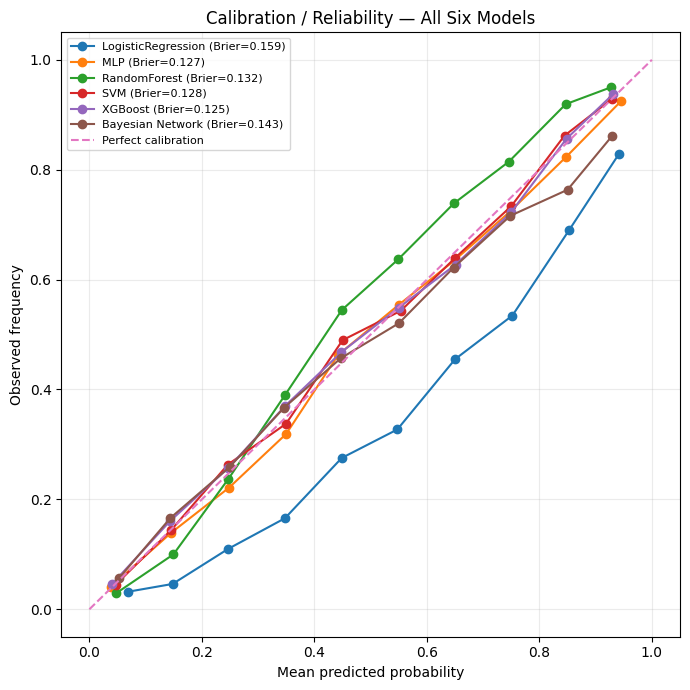

In [36]:

# Calibration for all six models.
calibration_rows = []
plt.figure(figsize=(7,7))

for model_name, d in all_models.items():
    prob_true, prob_pred = calibration_curve(y_test, d["prob"], n_bins=10, strategy="uniform")
    brier = brier_score_loss(y_test, d["prob"])
    pd.DataFrame({
        "model": model_name,
        "mean_predicted_probability": prob_pred,
        "observed_frequency": prob_true,
        "brier_score": brier
    }).to_csv(DIRS["results"] / f"calibration_{model_name.replace(' ','_')}.csv", index=False)
    calibration_rows.append({"Model": model_name, "Brier_Score": brier})
    plt.plot(prob_pred, prob_true, marker="o", label=f"{model_name} (Brier={brier:.3f})")

plt.plot([0,1], [0,1], linestyle="--", label="Perfect calibration")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed frequency")
plt.title("Calibration / Reliability — All Six Models")
plt.legend(fontsize=8)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(DIRS["figures"] / "FINAL_RQ1_reliability_all_models.png", dpi=180)
plt.show()

pd.DataFrame(calibration_rows).to_csv(DIRS["results"] / "FINAL_RQ1_calibration_summary.csv", index=False)


## 10. DeLong comparisons + Holm correction

In [37]:

def _compute_midrank(x):
    J = np.argsort(x); Z = x[J]; N = len(x)
    T = np.zeros(N, dtype=float); i = 0
    while i < N:
        j = i
        while j < N and Z[j] == Z[i]:
            j += 1
        T[i:j] = 0.5 * (i + j - 1) + 1
        i = j
    T2 = np.empty(N, dtype=float); T2[J] = T
    return T2

def _fast_delong(preds_sorted_transposed, label_1_count):
    m = label_1_count
    n = preds_sorted_transposed.shape[1] - m
    positive_examples = preds_sorted_transposed[:, :m]
    negative_examples = preds_sorted_transposed[:, m:]
    k = preds_sorted_transposed.shape[0]
    tx = np.empty([k,m]); ty = np.empty([k,n]); tz = np.empty([k,m+n])
    for r in range(k):
        tx[r,:] = _compute_midrank(positive_examples[r,:])
        ty[r,:] = _compute_midrank(negative_examples[r,:])
        tz[r,:] = _compute_midrank(preds_sorted_transposed[r,:])
    aucs = tz[:, :m].sum(axis=1)/m/n - (m+1.0)/(2.0*n)
    v01 = (tz[:, :m] - tx)/n
    v10 = 1.0 - (tz[:, m:] - ty)/m
    sx = np.cov(v01); sy = np.cov(v10)
    return aucs, sx/m + sy/n

def delong_roc_test(y_true, prob_a, prob_b):
    y_true = np.asarray(y_true)
    order = np.argsort(-y_true)
    m = int(np.sum(y_true[order] == 1))
    preds = np.vstack([prob_a, prob_b])[:, order]
    aucs, cov = _fast_delong(preds, m)
    l = np.array([1,-1])
    z = (l @ aucs) / np.sqrt(l @ cov @ l)
    p = 2 * (1 - norm.cdf(abs(z)))
    return float(aucs[0]), float(aucs[1]), float(z), float(p)

delong_rows = []
model_names = list(all_models.keys())
for a, b in itertools.combinations(model_names, 2):
    auc_a, auc_b, z, p = delong_roc_test(y_test, all_models[a]["prob"], all_models[b]["prob"])
    delong_rows.append({
        "Model_A": a,
        "Model_B": b,
        "AUROC_A": auc_a,
        "AUROC_B": auc_b,
        "AUROC_difference_A_minus_B": auc_a - auc_b,
        "z": z,
        "raw_p": p
    })

delong_df = pd.DataFrame(delong_rows)
reject, p_holm, _, _ = multipletests(delong_df["raw_p"], alpha=0.05, method="holm")
delong_df["holm_adjusted_p"] = p_holm
delong_df["holm_significant"] = reject

delong_df.to_csv(DIRS["results"] / "FINAL_RQ1_DeLong_15_comparisons_Holm.csv", index=False)
print(delong_df.to_string(index=False))


           Model_A          Model_B  AUROC_A  AUROC_B  AUROC_difference_A_minus_B          z        raw_p  holm_adjusted_p  holm_significant
LogisticRegression              MLP 0.844656 0.864410                   -0.019754 -10.443685 0.000000e+00     0.000000e+00              True
LogisticRegression     RandomForest 0.844656 0.861053                   -0.016397  -8.527588 0.000000e+00     0.000000e+00              True
LogisticRegression              SVM 0.844656 0.862596                   -0.017940  -9.738802 0.000000e+00     0.000000e+00              True
LogisticRegression          XGBoost 0.844656 0.868939                   -0.024283 -12.565574 0.000000e+00     0.000000e+00              True
LogisticRegression Bayesian Network 0.844656 0.827462                    0.017194   7.922488 2.220446e-15     1.554312e-14              True
               MLP     RandomForest 0.864410 0.861053                    0.003357   2.017568 4.363631e-02     1.309089e-01             False
             

## 11. BN sensitivity analysis

In [38]:

# Lightweight, checkpointed sensitivity analysis requested by the supervisor.
# The main BN remains the proposal-specification: BIC, max_indegree=3.
# Sensitivity uses the same training data and test partition.
SENSITIVITY_CONFIGS = [
    {"name": "max_parents_3", "max_indegree": 3, "score": "bic"},
    {"name": "max_parents_4", "max_indegree": 4, "score": "bic"},
    {"name": "max_parents_5", "max_indegree": 5, "score": "bic"},
]

from pgmpy.estimators import K2, BDeu as BDeuScore

sens_rows = []
for cfg in SENSITIVITY_CONFIGS:
    out_path = DIRS["results"] / f"FINAL_RQ1_BN_sensitivity_{cfg['name']}.csv"
    if out_path.exists():
        print("RESUME:", out_path.name)
        sens_rows.append(pd.read_csv(out_path).iloc[0].to_dict())
        continue

    scorer = BIC(X_train_bn)
    hc = HillClimbSearch(X_train_bn)
    learned = hc.estimate(
        scoring_method=scorer,
        tabu_length=10,
        max_indegree=cfg["max_indegree"],
        show_progress=False
    )
    temp_bn = DiscreteBayesianNetwork(list(learned.edges()))
    temp_bn.add_nodes_from(X_train_bn.columns)
    temp_est = BayesianEstimator(temp_bn, X_train_bn)
    for cpd in temp_est.get_parameters(prior_type="BDeu", equivalent_sample_size=1):
        temp_bn.add_cpds(cpd)
    assert temp_bn.check_model()

    temp_infer = VariableElimination(temp_bn)
    probs = []
    for _, row in X_test_bn.iterrows():
        ev = {v: row[v] for v in X_test_bn.columns if v != TARGET}
        q = temp_infer.query([TARGET], evidence=ev, show_progress=False)
        probs.append(float(q.values[[str(s) for s in q.state_names[TARGET]].index("1")]))

    auc = roc_auc_score(y_test, probs)
    row = {"configuration": cfg["name"], "max_indegree": cfg["max_indegree"], "test_AUROC": auc, "n_edges": len(temp_bn.edges())}
    pd.DataFrame([row]).to_csv(out_path, index=False)
    sens_rows.append(row)

pd.DataFrame(sens_rows).to_csv(DIRS["results"] / "FINAL_RQ1_BN_sensitivity_summary.csv", index=False)
print(pd.DataFrame(sens_rows).to_string(index=False))


RESUME: FINAL_RQ1_BN_sensitivity_max_parents_3.csv
RESUME: FINAL_RQ1_BN_sensitivity_max_parents_4.csv
RESUME: FINAL_RQ1_BN_sensitivity_max_parents_5.csv
configuration  max_indegree  test_AUROC  n_edges
max_parents_3             3    0.825029      151
max_parents_4             4    0.833031      162
max_parents_5             5    0.837689      165


In [40]:

import numpy as np
import pandas as pd

from sklearn.metrics import roc_auc_score, brier_score_loss
from pgmpy.estimators import HillClimbSearch, BIC, BayesianEstimator
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.inference import VariableElimination

# Three existing BN sensitivity configurations
SENSITIVITY_CONFIGS = [
    {"name": "max_parents_3", "max_indegree": 3},
    {"name": "max_parents_4", "max_indegree": 4},
    {"name": "max_parents_5", "max_indegree": 5},
]

sens_rows = []

for cfg in SENSITIVITY_CONFIGS:
    print(f"Evaluating {cfg['name']}...")

    # Learn the network structure using the training data
    scorer = BIC(X_train_bn)
    hc = HillClimbSearch(X_train_bn)

    learned = hc.estimate(
        scoring_method=scorer,
        tabu_length=10,
        max_indegree=cfg["max_indegree"],
        show_progress=False
    )

    # Fit the BN parameters
    temp_bn = DiscreteBayesianNetwork(
        list(learned.edges())
    )
    temp_bn.add_nodes_from(X_train_bn.columns)

    estimator = BayesianEstimator(temp_bn, X_train_bn)

    for cpd in estimator.get_parameters(
        prior_type="BDeu",
        equivalent_sample_size=1
    ):
        temp_bn.add_cpds(cpd)

    assert temp_bn.check_model()

    # Generate test-set probabilities FIRST
    temp_infer = VariableElimination(temp_bn)
    probs = []

    for _, row in X_test_bn.iterrows():
        evidence = {
            col: row[col]
            for col in X_test_bn.columns
            if col != TARGET
        }

        q = temp_infer.query(
            [TARGET],
            evidence=evidence,
            show_progress=False
        )

        states = [str(s) for s in q.state_names[TARGET]]
        positive_index = states.index("1")

        probs.append(float(q.values[positive_index]))

    # Calculate metrics only AFTER probs has been populated
    y_true = np.asarray(y_test, dtype=int)
    probs = np.asarray(probs, dtype=float)

    auc = roc_auc_score(y_true, probs)
    brier = brier_score_loss(y_true, probs)

    result = {
        "configuration": cfg["name"],
        "max_indegree": cfg["max_indegree"],
        "test_AUROC": auc,
        "test_Brier": brier,
        "n_edges": len(temp_bn.edges())
    }

    sens_rows.append(result)
    print(result)

# Save the new results without overwriting your old files
results_df = pd.DataFrame(sens_rows)

results_df.to_csv(
    DIRS["results"] /
    "FINAL_RQ1_BN_sensitivity_summary_with_brier.csv",
    index=False
)

print("\nFINAL SENSITIVITY RESULTS")
print(results_df.to_string(index=False))
print("\nResults saved successfully.")


Evaluating max_parents_3...


KeyboardInterrupt: 

In [41]:
import statsmodels.api as sm

calibration_slope_rows = []

for model_name, d in all_models.items():
    p = np.clip(
        np.asarray(d["prob"], dtype=float),
        1e-6,
        1 - 1e-6
    )

    logit_p = np.log(p / (1 - p))

    X_cal = sm.add_constant(
        pd.DataFrame({
            "logit_predicted_probability": logit_p
        })
    )

    y_cal = np.asarray(y_test, dtype=int)

    fit = sm.Logit(y_cal, X_cal).fit(disp=False)

    ci = fit.conf_int()

    calibration_slope_rows.append({
        "Model": model_name,
        "Calibration_Intercept":
            float(fit.params["const"]),
        "Calibration_Slope":
            float(fit.params["logit_predicted_probability"]),
        "Slope_CI_Low":
            float(ci.loc["logit_predicted_probability", 0]),
        "Slope_CI_High":
            float(ci.loc["logit_predicted_probability", 1])
    })

calibration_slopes = pd.DataFrame(calibration_slope_rows)

calibration_slopes.to_csv(
    DIRS["results"] / "FINAL_RQ1_calibration_slopes.csv",
    index=False
)

print(calibration_slopes.to_string(index=False))

             Model  Calibration_Intercept  Calibration_Slope  Slope_CI_Low  Slope_CI_High
LogisticRegression              -0.953412           0.992452      0.956785       1.028119
               MLP              -0.078373           0.963120      0.927677       0.998563
      RandomForest               0.299452           1.329940      1.280888       1.378992
               SVM               0.015905           1.011020      0.975889       1.046150
           XGBoost               0.020068           0.952988      0.919855       0.986120
  Bayesian Network              -0.088899           0.887307      0.854637       0.919976


In [42]:

%pip install -q pgmpy

import pgmpy

print("pgmpy version:", pgmpy.__version__)

from pgmpy.estimators import (
    HillClimbSearch,
    BIC,
    BayesianEstimator,
    TreeSearch,
    ExpertKnowledge
)

print("All required imports successful.")


pgmpy version: 1.1.2
All required imports successful.


In [43]:

# ================================================================
# RQ1: ADDITIONAL BAYESIAN NETWORK SENSITIVITY EXPERIMENTS
# ================================================================
# Requires the existing RQ1 notebook's final train/test splits,
# X_train_bn, X_test_bn, X_train_raw, y_train, y_test,
# discretization_map, TARGET, DIRS and BN feature definitions.
#
# Outputs:
#   FINAL_RQ1_BN_sensitivity_discretisation.csv
#   FINAL_RQ1_BN_sensitivity_structure_learning.csv
#   FINAL_RQ1_BN_sensitivity_parameter_estimation.csv
#   FINAL_RQ1_BN_sensitivity_graph_restrictions.csv
#   FINAL_RQ1_BN_sensitivity_extra_variants.csv
# ================================================================

import numpy as np
import pandas as pd
import pickle
from pathlib import Path

from sklearn.metrics import roc_auc_score, brier_score_loss

from pgmpy.estimators import (
    HillClimbSearch,
    BIC,
    BayesianEstimator,
    TreeSearch,
    ExpertKnowledge
)
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.inference import VariableElimination


# ------------------------------------------------
# 0. Verify the notebook is prepared
# ------------------------------------------------
required_variables = [
    "X_train_raw",
    "X_test_raw",
    "X_train_bn",
    "X_test_bn",
    "y_train",
    "y_test",
    "discretization_map",
    "comorbidity_cols",
    "true_categorical_cols",
    "TARGET",
    "DIRS"
]

missing = [
    name for name in required_variables
    if name not in globals()
]

if missing:
    raise NameError(
        "Run the earlier RQ1 data preparation and BN cells first. "
        f"Missing variables: {missing}"
    )

RESULTS_DIR = Path(DIRS["results"])
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Preserve the target's original binary labels for scoring.
y_train_array = np.asarray(y_train, dtype=int)
y_test_array = np.asarray(y_test, dtype=int)

assert len(X_train_bn) == len(y_train_array)
assert len(X_test_bn) == len(y_test_array)
assert TARGET in X_train_bn.columns
assert TARGET in X_test_bn.columns

print("Training records:", len(X_train_bn))
print("Test records:", len(X_test_bn))
print("Target:", TARGET)


# ------------------------------------------------
# 1. Helper: fit a network with supplied edges
# ------------------------------------------------
def fit_bn_with_edges(train_data, edges, prior="BDeu"):
    """Fit BN conditional probability tables on training data only."""
    model = DiscreteBayesianNetwork(list(edges))
    model.add_nodes_from(train_data.columns)

    estimator = BayesianEstimator(model, train_data)

    if prior == "K2":
        cpds = estimator.get_parameters(prior_type="K2")
    elif prior == "BDeu":
        cpds = estimator.get_parameters(
            prior_type="BDeu",
            equivalent_sample_size=1
        )
    else:
        raise ValueError(f"Unsupported parameter prior: {prior}")

    for cpd in cpds:
        model.add_cpds(cpd)

    if not model.check_model():
        raise ValueError("The fitted Bayesian Network failed validation.")

    return model


# ------------------------------------------------
# 2. Helper: learn a graph using BIC hill climbing
# ------------------------------------------------
def learn_bic_graph(train_data, expert_knowledge=None):
    """Use BIC hill climbing with maximum indegree 3."""
    hc = HillClimbSearch(train_data)

    kwargs = {
        "scoring_method": BIC(train_data),
        "tabu_length": 10,
        "max_indegree": 3,
        "show_progress": False
    }

    if expert_knowledge is not None:
        kwargs["expert_knowledge"] = expert_knowledge

    learned_dag = hc.estimate(**kwargs)
    return list(learned_dag.edges())


# ------------------------------------------------
# 3. Helper: evaluate probabilities on the held-out test set
# ------------------------------------------------
def evaluate_bn(model, test_data, y_true, configuration):
    """Return AUROC, Brier score, and network edge count."""
    inference = VariableElimination(model)
    probs = []

    for i, (_, row) in enumerate(test_data.iterrows(), start=1):
        evidence = {
            col: row[col]
            for col in test_data.columns
            if col != TARGET
        }

        q = inference.query(
            [TARGET],
            evidence=evidence,
            show_progress=False
        )

        states = [str(s) for s in q.state_names[TARGET]]

        if "1" not in states:
            raise ValueError(
                f"Positive HF state '1' not found for {configuration}."
            )

        probs.append(float(q.values[states.index("1")]))

        if i % 1000 == 0:
            print(
                f"{configuration}: "
                f"evaluated {i:,}/{len(test_data):,} test records"
            )

    probs = np.asarray(probs, dtype=float)
    y_true = np.asarray(y_true, dtype=int)

    if len(probs) != len(y_true):
        raise ValueError("Prediction count does not match test labels.")

    result = {
        "configuration": configuration,
        "test_AUROC": roc_auc_score(y_true, probs),
        "test_Brier": brier_score_loss(y_true, probs),
        "n_edges": len(model.edges())
    }

    print("Result:", result)
    return result


# ------------------------------------------------
# 4. Helper: construct BN data using a discretisation map
# ------------------------------------------------
def make_bn_frame(raw_data, labels, disc_map):
    """Create a BN-ready frame with the same feature definitions."""
    continuous = pd.DataFrame(index=raw_data.index)

    for col, (bins, bin_labels) in disc_map.items():
        if col not in raw_data.columns:
            continue

        numeric_values = pd.to_numeric(
            raw_data[col],
            errors="coerce"
        )

        continuous[col] = pd.cut(
            numeric_values,
            bins=bins,
            labels=bin_labels,
            include_lowest=True
        )

    categorical_candidates = list(dict.fromkeys(
        list(comorbidity_cols) + list(true_categorical_cols)
    ))

    categorical = [
        col for col in categorical_candidates
        if col in raw_data.columns and col not in continuous.columns
    ]

    blocks = [continuous]

    if categorical:
        blocks.append(raw_data[categorical].astype("category"))

    frame = pd.concat(blocks, axis=1)
    frame = frame.loc[:, ~frame.columns.duplicated()]

    frame[TARGET] = pd.Series(
        np.asarray(labels).astype(str),
        index=raw_data.index,
        name=TARGET
    )

    return frame.astype(str)


# Collect results as experiments finish.
extra_results = []


# ================================================================
# EXPERIMENT 1: ALTERNATIVE DISCRETISATION
# Three-bin quantile discretisation learned from training data only.
# ================================================================
print("\n========== EXPERIMENT 1: ALTERNATIVE DISCRETISATION ==========")

quantile_map = {}

for col in discretization_map:
    if col not in X_train_raw.columns:
        continue

    values = pd.to_numeric(
        X_train_raw[col],
        errors="coerce"
    ).dropna()

    # Quantile boundaries come from training data only.
    cuts = np.unique(
        values.quantile([1/3, 2/3]).dropna().to_numpy()
    )

    edges = [-np.inf] + cuts.tolist() + [np.inf]
    labels = [f"Q{i+1}" for i in range(len(edges) - 1)]

    quantile_map[col] = (edges, labels)

if not quantile_map:
    raise ValueError(
        "No continuous features were available for alternative discretisation."
    )

X_train_quantile = make_bn_frame(
    X_train_raw,
    y_train,
    quantile_map
)

X_test_quantile = make_bn_frame(
    X_test_raw,
    y_test,
    quantile_map
)

if list(X_train_quantile.columns) != list(X_test_quantile.columns):
    raise ValueError(
        "Training and test feature columns differ after discretisation."
    )

# Same BIC search limit and BDeu parameter estimation for this variant.
quantile_edges = learn_bic_graph(X_train_quantile)

quantile_model = fit_bn_with_edges(
    X_train_quantile,
    quantile_edges,
    prior="BDeu"
)

result = evaluate_bn(
    quantile_model,
    X_test_quantile,
    y_test_array,
    "alternative_discretisation_quantile_tertiles"
)

result.update({
    "sensitivity_axis": "discretisation",
    "structure_method": "BIC hill climbing",
    "parameter_estimation": "BDeu, ESS=1"
})

extra_results.append(result)

pd.DataFrame([result]).to_csv(
    RESULTS_DIR / "FINAL_RQ1_BN_sensitivity_discretisation.csv",
    index=False
)


# ================================================================
# EXPERIMENT 2: ALTERNATIVE STRUCTURE LEARNING
# Chow-Liu tree learning; parameter estimation remains BDeu.
# ================================================================
print("\n========== EXPERIMENT 2: STRUCTURE LEARNING ==========")

tree_search = TreeSearch(
    X_train_bn,
    root_node=TARGET,
    n_jobs=1
)

tree_dag = tree_search.estimate(
    estimator_type="chow-liu",
    edge_weights_fn="mutual_info",
    show_progress=False
)

tree_model = fit_bn_with_edges(
    X_train_bn,
    list(tree_dag.edges()),
    prior="BDeu"
)

result = evaluate_bn(
    tree_model,
    X_test_bn,
    y_test_array,
    "alternative_structure_learning_chow_liu"
)

result.update({
    "sensitivity_axis": "structure learning",
    "structure_method": "Chow-Liu tree",
    "parameter_estimation": "BDeu, ESS=1"
})

extra_results.append(result)

pd.DataFrame([result]).to_csv(
    RESULTS_DIR / "FINAL_RQ1_BN_sensitivity_structure_learning.csv",
    index=False
)


# ================================================================
# EXPERIMENT 3: ALTERNATIVE PARAMETER ESTIMATION
# Keep the main consensus graph; change BDeu to the K2 prior.
# ================================================================
print("\n========== EXPERIMENT 3: PARAMETER ESTIMATION ==========")

# Reuse the main graph structure but refit its CPDs from training data.
if "consensus_model" in globals():
    main_graph_edges = list(consensus_model.edges())
else:
    saved_model_path = DIRS["models"] / "FINAL_bayesian_network.pkl"

    if not saved_model_path.exists():
        raise FileNotFoundError(
            "The main graph was not found. Run the main BN fitting cell first."
        )

    with open(saved_model_path, "rb") as file:
        saved_main_model = pickle.load(file)

    main_graph_edges = list(saved_main_model.edges())

k2_model = fit_bn_with_edges(
    X_train_bn,
    main_graph_edges,
    prior="K2"
)

result = evaluate_bn(
    k2_model,
    X_test_bn,
    y_test_array,
    "alternative_parameter_estimation_K2"
)

result.update({
    "sensitivity_axis": "parameter estimation",
    "structure_method": "Fixed main consensus graph",
    "parameter_estimation": "K2 prior"
})

extra_results.append(result)

pd.DataFrame([result]).to_csv(
    RESULTS_DIR / "FINAL_RQ1_BN_sensitivity_parameter_estimation.csv",
    index=False
)


# ================================================================
# EXPERIMENT 4: GRAPH RESTRICTIONS
# Constrain heart_failure to have no incoming edges.
# This treats HF as a disease node that can influence findings.
# ================================================================
print("\n========== EXPERIMENT 4: GRAPH RESTRICTIONS ==========")

predictor_nodes = [
    col for col in X_train_bn.columns
    if col != TARGET
]

# Forbid predictor -> HF edges, allowing HF -> clinical findings.
forbidden_edges = [
    (predictor, TARGET)
    for predictor in predictor_nodes
]

expert = ExpertKnowledge(
    forbidden_edges=forbidden_edges
)

restricted_edges = learn_bic_graph(
    X_train_bn,
    expert_knowledge=expert
)

restricted_model = fit_bn_with_edges(
    X_train_bn,
    restricted_edges,
    prior="BDeu"
)

result = evaluate_bn(
    restricted_model,
    X_test_bn,
    y_test_array,
    "graph_restriction_HF_as_root"
)

result.update({
    "sensitivity_axis": "graph restrictions",
    "structure_method": "BIC hill climbing with edge constraints",
    "parameter_estimation": "BDeu, ESS=1"
})

extra_results.append(result)

pd.DataFrame([result]).to_csv(
    RESULTS_DIR / "FINAL_RQ1_BN_sensitivity_graph_restrictions.csv",
    index=False
)


# ================================================================
# 5. Save the four companion variants together
# ================================================================
extra_df = pd.DataFrame(extra_results)

extra_path = (
    RESULTS_DIR / "FINAL_RQ1_BN_sensitivity_extra_variants.csv"
)

extra_df.to_csv(extra_path, index=False)

print("\n========== EXTRA SENSITIVITY RESULTS ==========")
print(extra_df.to_string(index=False))
print("\nSaved combined results to:", extra_path)


# ================================================================
# 6. Optionally combine with the three max-parent results
# Only merge if those results include their Brier scores.
# ================================================================
base_path = (
    RESULTS_DIR / "FINAL_RQ1_BN_sensitivity_summary_with_brier.csv"
)

extended_path = (
    RESULTS_DIR / "FINAL_RQ1_BN_sensitivity_extended.csv"
)

if base_path.exists():
    base_df = pd.read_csv(base_path)

    if "test_Brier" in base_df.columns and base_df["test_Brier"].notna().all():
        extended_df = pd.concat(
            [base_df, extra_df],
            ignore_index=True,
            sort=False
        )

        extended_df.to_csv(extended_path, index=False)

        print("\nSaved full sensitivity table to:", extended_path)
        print(extended_df.to_string(index=False))
    else:
        print(
            "\nThe max-parent summary exists but does not contain Brier scores "
            "for every configuration. Run the corrected max-parent sensitivity "
            "cell before creating the full extended table."
        )
else:
    print(
        "\nThe four companion CSVs are saved. To create a combined table, "
        "first generate FINAL_RQ1_BN_sensitivity_summary_with_brier.csv "
        "for max-parent configurations 3, 4 and 5."
    )


Training records: 66170
Test records: 14096
Target: heart_failure

========== EXPERIMENT 1: ALTERNATIVE DISCRETISATION ==========
alternative_discretisation_quantile_tertiles: evaluated 1,000/14,096 test records
alternative_discretisation_quantile_tertiles: evaluated 2,000/14,096 test records
alternative_discretisation_quantile_tertiles: evaluated 3,000/14,096 test records
alternative_discretisation_quantile_tertiles: evaluated 4,000/14,096 test records
alternative_discretisation_quantile_tertiles: evaluated 5,000/14,096 test records
alternative_discretisation_quantile_tertiles: evaluated 6,000/14,096 test records
alternative_discretisation_quantile_tertiles: evaluated 7,000/14,096 test records
alternative_discretisation_quantile_tertiles: evaluated 8,000/14,096 test records
alternative_discretisation_quantile_tertiles: evaluated 9,000/14,096 test records
alternative_discretisation_quantile_tertiles: evaluated 10,000/14,096 test records
alternative_discretisation_quantile_tertiles: eva

## 12. Final RQ1 artifact

The final RQ1 result table is written to:

`MyDrive/heart_failure_bn_FINAL/results/FINAL_RQ1_ALL_6_MODELS.csv`

Every model, prediction array, parameter file and BN bootstrap progress file is saved under the same Drive project folder, so a Colab restart can resume completed work rather than retraining it.
